# 01. E-Commerce Order Data Quality Audit & Cleaning Methods

### Auditing 10,000 raw transaction records prior to data cleaning

#### Table of Contents:


## 1. Environment Setup and Raw Schema Profiling

#### Load raw data and check baseline health

In [139]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='viridis', context='notebook')


#### Dataframe Profiling 

In [140]:
df_raw = pd.read_csv(r"data\raw\ecommerce_orders_data.csv",dtype='str')
df = df_raw.copy()
def df_profile(df):
    '''A function to get information about a DataFrame'''
    info = pd.DataFrame({
        'Data Type': df.dtypes,
        'Non-Null Count' : df.notna().sum(),
        'Null Count': df.isna().sum(),
        'Null%' : (df.isna().mean()*100).round(2),
        'Unique Values': df.nunique().astype('int64'),
        'Memory_Usage(in KB)': (df.memory_usage()/1024).round(2)
    })
    info = info.drop('Index',axis=0)
    return info

df_profile(df_raw)

,Data Type,Non-Null Count,Null Count,Null%,Unique Values,Memory_Usage(in KB)
Customer_Age,str,9750.0,250.0,2.50,62.0,78.12
Customer_Email,str,9627.0,373.0,3.73,9364.0,78.12
Is_Returned,str,9710.0,290.0,2.90,12.0,78.12
Order_Amount,str,9782.0,218.0,2.18,9501.0,78.12
Order_Date,str,9801.0,199.0,1.99,9715.0,78.12
Order_ID,str,10000.0,0.0,0.00,9856.0,78.12
Payment_Method,str,9752.0,248.0,2.48,26.0,78.12


#### Priliminary inspection

In [141]:
id_dup = df['Order_ID'].duplicated().sum()
print("No. of Duplicate Order IDs: ",id_dup)
is_retrnd_uniq = list(df['Is_Returned'].unique())
print("Values in the Is_Returned column: ",is_retrnd_uniq,'\n')

order_amt_uniq = df['Order_Amount'].value_counts()[:5]
print("Values in Order Amount column: ",order_amt_uniq,'\n')

order_date_uniq = df['Order_Date'].value_counts()[:5]
print("Values in Order Date Column:",order_date_uniq)

No. of Duplicate Order IDs:  144
Values in the Is_Returned column:  ['False', 'True', nan, 'Yes', '1', 'TRUE', 'not returned', 'Y', 'FALSE', 'N', '0', 'No', 'returned'] 

Values in Order Amount column:  Order_Amount
9999999.99    35
₹1,250.00     35
2564.21        3
521.19         3
1970.15        3
Name: count, dtype: int64 

Values in Order Date Column: Order_Date
00-00-0000             16
31/13/2025             10
2025-02-30              8
not-a-date              6
2026-05-01 01:34:19     2
Name: count, dtype: int64


## 2. String normalization and Primary key deduplication

#### Enforce primary key integrity before performing any statistical aggregations

In [142]:
#To begin cleaning, we will start by performing dataframe wide operations.
# since all columns are in str format, we will apply the strip(), lower() functions
# to remove trailing whitespaces and get the values in a uniform format. Then change order_ID to upper
df = df.apply(lambda x: x.str.strip().str.lower())
df.iloc[:,0] = df.iloc[:,0].str.upper()
df.head(10)

,Order_ID,Customer_Age,Order_Amount,Order_Date,Payment_Method,Is_Returned,Customer_Email
0,ORD104099,32.0,1430.09,2026-08-15 06:05:10,upi,false,customer4099@outlook.com
1,ORD108672,36.0,3340.73,2025-05-09 00:25:06,wallet,false,customer8672@example.com
2,ORD107467,24.0,2724.27,2025-06-20 18:31:44,wallet,true,customer7467@yahoo.com
3,ORD100738,62.0,813.43,2026-07-01 15:39:18,wallet,false,customer738@yahoo.com
4,ORD105622,70.0,209.92,2026-07-24 08:20:24,debit card,false,customer5622@gmail.com
5,ORD105955,51.0,8775.61,2026-05-13 07:05:53,upi,false,customer5955@outlook.com
6,ORD103198,75.0,6702.32,2025-02-26 05:54:08,cash on delivery,false,NaN
7,ORD107185,34.0,625.16,2025-05-05 06:52:56,credit card,false,customer7185@gmail.com
8,ORD107658,26.0,1602.58,2026-08-28 17:14:56,wallet,false,customer7658@yahoo.com
9,ORD103044,57.0,1852.26,2025-01-08 16:49:47,debit card,false,customer3044@yahoo.com


Remove entire duplicate rows and duplicate Order_ID columns

In [143]:
#Total complete duplicate rows
print(f"Total Duplicate rows: {df.duplicated().sum()}")
#We will keep the first and remove all duplicate occurances
print('Total Rows: ',df.shape[0])
df = df.drop_duplicates()
print('Total Rows after removing duplicates: ',df.shape[0])

#Duplicate value in the Order_ID column.
print('Duplicates on the Order_ID column: ',df.duplicated(subset='Order_ID').sum())

#Duplicate Order_ID rows
dup_orders = df[df['Order_ID'].isin(df['Order_ID'].value_counts().index[:2])].sort_values(by='Order_ID')
print("Example of columns with same Order_IDs: \n",dup_orders)

#Since Order_ID is the primary key of our table, we cannot have duplicate values in it. We will remove all duplicate entries except for the first one
df = df.drop_duplicates(subset='Order_ID')
print(df.head())
#Checking for same orders with different Order_ID
print("No. of same orders with different orderID: ",df.iloc[1:,:].duplicated().sum())
assert df['Order_ID'].is_unique
#No same orders with different orderIDs. Duplicate order_IDs removed

Total Duplicate rows: 45
Total Rows:  10000
Total Rows after removing duplicates:  9955
Duplicates on the Order_ID column:  99
Example of columns with same Order_IDs: 
        Order_ID Customer_Age Order_Amount           Order_Date  \
79    ORD100916         46.0       593.69  2025-07-14 19:18:38   
3861  ORD100916         61.0       1017.9  2025-06-03 17:08:20   
1990  ORD100942         57.0       791.53  2026-04-07 16:59:18   
5809  ORD100942         40.0      1327.08  2026-02-02 11:58:04   
6539  ORD100942         46.0       1193.4  2026-02-22 04:31:44   

        Payment_Method Is_Returned            Customer_Email  
79    cash on delivery       false   customer916@outlook.com  
3861       net banking       false  customer9561@example.com  
1990       net banking        true     customer942@yahoo.com  
5809       credit card       false                       NaN  
6539       credit card       false  customer1577@example.com  
    Order_ID Customer_Age Order_Amount           Order_D

## 3. Numeric and Financial Field Treatment (Customer_Age & Order_Amount)

#### Parse corrupted numeric strings, isolate placeholder values

Clean Customer_Age column

In [144]:
#We will clean the Customer_Age column
#First we will check all the distinct values present in the column
print("Unique Customer_Age values: \n",df['Customer_Age'].unique())
#From our initial analysis we can tell that there are a few invalid values like 'unknown', '-1.0', 'thirty', '150.0'
#From all these invalid data, We can retain the 'thirty' if we convert it to numeric format.
print(df.query("Customer_Age == 'thirty'").head())
#We can see that quite a few entries have 'thirty' as age. This might be cause due to a misunderstanding during data entry
#And we will salvage these rows by replacing them with numerical 30
df['Customer_Age'] = df['Customer_Age'].replace('thirty',30)
print(df['Customer_Age'].unique())
#Now we will change the datatype of the column to numeric. We do have some invalid entries that cannot be converted. But we can circumvent them using 'coerce'
df['Customer_Age'] = pd.to_numeric(df['Customer_Age'],errors='coerce')
print(df['Customer_Age'].unique())
#Now our column is in numeric type. We will remove the remaining invalid data, like -1, 150, etc.
df['Customer_Age'] = df['Customer_Age'].apply(lambda x: x if (x >= 18 and x <= 100) else np.nan)
#Lets convert the column to integer dtype
df['Customer_Age']=df['Customer_Age'].astype('Int64')
df['Customer_Age'].value_counts(dropna=False).index
#We can see that all our invalid and irregular data has been removed. We will clean up all columns and remove the nan at the end.

Unique Customer_Age values: 
 <StringArray>
[   '32.0',    '36.0',    '24.0',    '62.0',    '70.0',    '51.0',    '75.0',
    '34.0',    '26.0',    '57.0',    '45.0',    '23.0',    '29.0',    '69.0',
    '63.0',       nan,    '66.0',    '38.0',    '35.0',    '74.0',    '55.0',
    '46.0',    '33.0',    '49.0',    '68.0',    '20.0',    '21.0',    '56.0',
    '40.0',    '28.0',    '59.0',    '42.0',    '31.0',    '48.0',    '71.0',
    '41.0',    '43.0',    '22.0',    '47.0', 'unknown',    '67.0',    '27.0',
    '18.0',    '30.0',    '54.0',    '64.0',    '60.0',    '44.0',    '19.0',
    '50.0',    '25.0',    '73.0',    '58.0',    '39.0',    '72.0',    '61.0',
    '37.0',    '52.0',    '53.0',   '150.0',    '65.0',  'thirty',    '-1.0']
Length: 63, dtype: str
       Order_ID Customer_Age Order_Amount           Order_Date  \
209   ORD107914       thirty       615.63  2025-06-17 23:41:16   
561   ORD103809       thirty   9999999.99  2026-01-12 00:53:43   
753   ORD109073       thirty     

Index([<NA>,   25,   30,   73,   40,   56,   43,   38,   35,   52,   75,   20,
         61,   53,   32,   57,   55,   41,   47,   46,   28,   48,   72,   49,
         31,   59,   39,   36,   69,   74,   71,   58,   33,   45,   23,   21,
         24,   62,   22,   63,   34,   27,   64,   65,   44,   26,   54,   66,
         68,   42,   51,   29,   37,   60,   19,   67,   70,   18,   50],
      dtype='Int64', name='Customer_Age')

Clean Order_Amount column

All distinct Order_Amounts: 
 Index(['9999999.99', '₹1,250.00', '521.19', '1970.15', '813.43', '795.19',
       '1454.04', '956.36', '733.23', '1193.38',
       ...
       '809.87', '779.32', '1904.43', '1463.32', '1897.5', '1550.53',
       '2039.17', '1584.42', '599.65', '1471.96'],
      dtype='str', name='Order_Amount', length=9409)
Unique Values of Order_Amount after convertion to numeric: 
 Index([9999999.99,     1250.0,     521.19,    1970.15,     813.43,     795.19,
          1454.04,     956.36,     733.23,    1193.38,
       ...
           809.87,     779.32,    1904.43,    1463.32,     1897.5,    1550.53,
          2039.17,    1584.42,     599.65,    1471.96],
      dtype='float64', name='Order_Amount', length=9409)


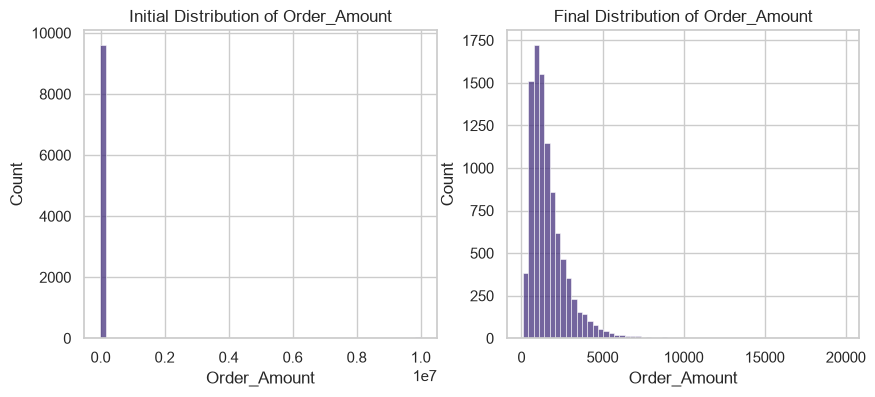

In [145]:
# Lets check all distinct values
print("All distinct Order_Amounts: \n",df['Order_Amount'].value_counts().index)
#We can see invalid characters like 999999.999, values that need cleaning like ₹1,250.00, etc.
#Lets clean the values
df['Order_Amount'] = df['Order_Amount'].replace('[$€£₹¥,]','',regex=True)
#We have removed the currency signs and commas and should be able to convert the column to numeric
df['Order_Amount'] = pd.to_numeric(df['Order_Amount'])
print("Unique Values of Order_Amount after convertion to numeric: \n",df['Order_Amount'].value_counts().index)

#Creating subplots to compare before and after
fig,axes = plt.subplots(1,2,figsize=(10,4))

#Our column is converted to numeric, without any errors. Lets check the distribution of our data.
sns.histplot(df['Order_Amount'],bins=60,ax=axes[0])
axes[0].set_title("Initial Distribution of Order_Amount")

#Lets remove the invalid entries that are skewing our distribution
df['Order_Amount'] = df['Order_Amount'].apply(lambda x : x if (x > 0 and x < 10_00_000) else np.nan )
df['Order_Amount'].value_counts(dropna=False).head()

sns.histplot(df['Order_Amount'],bins=60,ax=axes[1])
axes[1].set_title("Final Distribution of Order_Amount")

#We can observe that after removal of extreme outliers, our data is no longer heavily skewed. Although a bit of natural skewness is expected

plt.show()
#Export the graph
fig.tight_layout()
fig.savefig("./reports/01_order_amount_outlier_impact_comparison.png")
plt.close(fig)

## 4. Statistical Outlier Analysis (IQR vs. Z-Score Comparison)

#### Complete the statistical evaluation of legitimate high-value orders

In [146]:
print(df.describe())

#Detecting Outliers in the Order_Amount column using the IQR method

#We will calclate the q1 and q3
q1 = df['Order_Amount'].quantile(0.25)
q3 = df['Order_Amount'].quantile(0.75)
#The inter-quantile range is the Q3 - Q1
iqr = q3 - q1
#By default, the upper and lower bound are calculated on 1.5 times the IQR
#The lower bound for our calculation will be Q1 - 1.5*(iqr)
iqr_lower_bound = q1 - 1.5*iqr
#The upper bound for our calculation will be Q3 + 1.5*(iqr)
iqr_upper_bound = q3 + 1.5*iqr
#Lets check the outliers from our data
outliers_iqr = df.query("Order_Amount > @iqr_upper_bound or Order_Amount < @iqr_lower_bound")

print(outliers_iqr)
#A total of 469 outliers were detected from our data, but they are legitimate orders, so the default formula will not work here

       Customer_Age  Order_Amount
count        9510.0   9569.000000
mean      46.472345   1650.116424
std       16.673945   1203.836513
min            18.0    104.630000
25%            32.0    854.030000
50%            46.0   1329.770000
75%            61.0   2079.770000
max            75.0  19853.420000
       Order_ID  Customer_Age  Order_Amount           Order_Date  \
5     ORD105955            51       8775.61  2026-05-13 07:05:53   
6     ORD103198            75       6702.32  2025-02-26 05:54:08   
40    ORD105123            42       5125.78  2026-03-27 02:39:14   
56    ORD104512          <NA>       4455.12  2026-04-28 18:11:20   
90    ORD109563            35       6748.22  2025-09-09 09:02:42   
...         ...           ...           ...                  ...   
9868  ORD109811            20       4151.82  2026-08-21 07:31:32   
9959  ORD100260            57       4448.67  2025-04-02 18:04:42   
9960  ORD101336            46       4872.37  2025-06-16 23:56:24   
9961  ORD10784

In [147]:
#detecting outliers using the Z-score method

#The Z-Score method can only be applied to a distribution that is preferrably in normal distribution or not heavily skewed.
#So, lets check the distriution of our data first
print(f"Skeweness of original data: {df['Order_Amount'].skew()}")
#Our data is heavily skewed to the right. We will have to transform it using log first.
order_amount_log = np.log(df['Order_Amount'])
print(f"Skeweness of transformed data: {order_amount_log.skew()}")
#Now our data is very close to a normal distribution with a skewness value of 0.006
#Let's find the outliers using z-score method
#According to the z-score method, lower_bound is mean -3times standard_deviation  & upper_bound is mean + 3times standard_deviation.
#Any record outside this range is an outlier
zscore_lower_bound = order_amount_log.mean() - 3*order_amount_log.std()
zscore_upper_bound = order_amount_log.mean() + 3*order_amount_log.std()

outlier_map_zscore = (order_amount_log>zscore_upper_bound) | (order_amount_log<zscore_lower_bound) #outlier map
print(f"Total Outliers: {outlier_map_zscore.sum()}")
#According to our analysis we have 28 outliers in our data
outlier_zscore = df.loc[outlier_map_zscore]
print(outlier_zscore.head()) #Outliers

Skeweness of original data: 2.7846548372087674
Skeweness of transformed data: -0.006891976190992274
Total Outliers: 28
      Order_ID  Customer_Age  Order_Amount           Order_Date  \
165  ORD105807            71        169.27  2025-09-02 18:31:52   
452  ORD109768            35        143.53  2025-10-24 22:36:36   
523  ORD109867            25       9548.70  2026-09-03 07:11:56   
601  ORD109047            58      10618.06  2025-11-13 23:55:34   
633  ORD107427            40        177.77  2025-01-13 05:41:07   

       Payment_Method Is_Returned            Customer_Email  
165            wallet        true    customer5807@gmail.com  
452  cash on delivery       false  customer9768@outlook.com  
523        debit card       false    customer9867@yahoo.com  
601       net banking       false    customer9047@yahoo.com  
633       net banking        true  customer7427@example.com  


#### Comparision between the IQR and the Z-Score method:

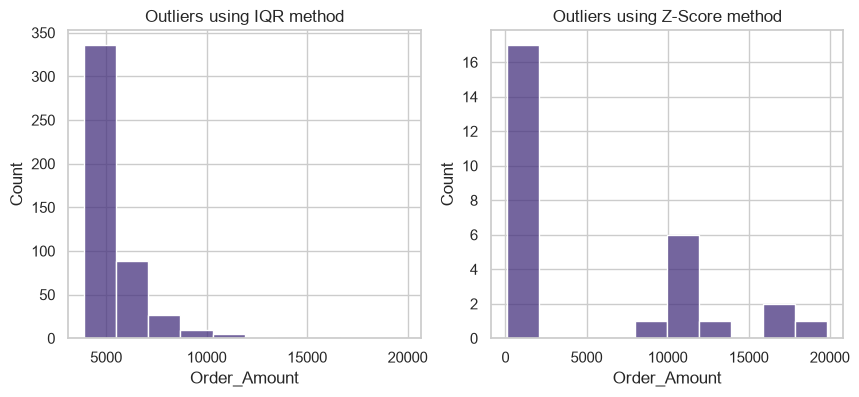

In [148]:
fig,axes = plt.subplots(1,2,figsize = (10,4))

sns.histplot(outliers_iqr['Order_Amount'],bins=10,ax=axes[0])
axes[0].set_title("Outliers using IQR method")

sns.histplot(outlier_zscore['Order_Amount'],bins=10,ax=axes[1])
axes[1].set_title("Outliers using Z-Score method")
plt.show()
fig.tight_layout()
fig.savefig("./reports/02_outlier_detection_methods_comparision.png")
plt.close()

## 5. Timedate parsing and Cutoff validation

#### Standardize mixed date formats, eliminate impossible calendar/future dates

Clean Order_Date column

In [149]:
#Lets check the values in the Order_Date column
print("Unique Order_Date values: \n",df['Order_Date'].value_counts(dropna=False).head(10))
#We can see there are some invalid dates and some incorrect values in the column. We cannot retrive any incorrect date values
#So, we will pass just convert the column to datetime and let any invalid entries to be converted to NaT
df['Order_Date'] = pd.to_datetime(df['Order_Date'],format='mixed',errors='coerce')
#We can see our column has been successfully parsed, with a good turnover rate
print(df['Order_Date'].value_counts(dropna=False).head(20))

Unique Order_Date values: 
 Order_Date
NaN                    197
00-00-0000              16
31/13/2025               9
2025-02-30               8
not-a-date               6
03/26/2026               2
03/16/2025               2
05/10/2026               2
24 jul 2025              2
2025-05-19 13:41:34      2
Name: count, dtype: int64
Order_Date
NaT                    236
2026-03-26 00:00:00      2
2026-07-02 00:00:00      2
2025-12-15 00:00:00      2
2025-03-16 00:00:00      2
2026-05-10 00:00:00      2
2025-02-28 00:00:00      2
2026-07-12 00:00:00      2
2025-07-24 00:00:00      2
2025-05-19 13:41:34      2
2026-08-27 00:00:00      2
2025-02-11 00:00:00      2
2026-09-14 00:00:00      2
2026-06-27 00:00:00      2
2026-02-18 00:00:00      2
2025-10-12 00:00:00      2
2026-06-21 00:00:00      2
2025-05-17 00:00:00      2
2026-09-13 00:00:00      2
2026-08-15 06:05:10      1
Name: count, dtype: int64


Clean dates after the date of extraction of data(i.e. future dates)

In [150]:
#Lets check if we have order dates from the future.
print("Future Dates: \n",df.loc[df['Order_Date'] > pd.to_datetime('2026/11/1')])
#As we can see, there are 4 records from November '26. These dates are from after I got the dataset. So, they are incorrect and must be removed.
df = df.drop((df.loc[df['Order_Date'] > pd.to_datetime('2026/11/1')].index))
#Lets verify if the dates from future are gone
print(df.loc[df['Order_Date'] > pd.to_datetime('2026/11/1')])
#Extracted day of the week
day_df = df['Order_Date'].dt.day_name()

#Creating a seperate Order_Year column
df['Order_Year'] = df['Order_Date'].dt.year.astype('Int64')
#Creating a seperate Order_Month column
df['Order_Month'] = df['Order_Date'].dt.month_name()
#Lets check our new columns
print(df[['Order_Date','Order_Month','Order_Year']].head(10))

Future Dates: 
        Order_ID  Customer_Age  Order_Amount Order_Date Payment_Method  \
7156  ORD108324            62        376.60 2026-12-08    net banking   
7265  ORD104154            66       1465.31 2026-11-03    credit card   
7726  ORD101964            63           NaN 2026-11-09         wallet   
7970  ORD102294            34       1640.98 2026-12-05            upi   

     Is_Returned            Customer_Email  
7156        true                       NaN  
7265       false  customer4154@outlook.com  
7726       false  customer1964@outlook.com  
7970       false    customer2294@gmail.com  
Empty DataFrame
Columns: [Order_ID, Customer_Age, Order_Amount, Order_Date, Payment_Method, Is_Returned, Customer_Email]
Index: []
           Order_Date Order_Month  Order_Year
0 2026-08-15 06:05:10      August        2026
1 2025-05-09 00:25:06         May        2025
2 2025-06-20 18:31:44        June        2025
3 2026-07-01 15:39:18        July        2026
4 2026-07-24 08:20:24        Jul

## 6. Categorical, Boolean & Contact Validation

#### Standardize messy categorical labels, enforce nullable booleans, and validate email syntax

Clean Payment_Methods column

Unique Payment_Method values before Cleaning: Payment_Method
wallet              1636
upi                 1622
net banking         1609
credit card         1564
debit card          1562
cash on delivery    1533
NaN                  242
debitcard             24
cod                   24
unknown               23
crypto                13
Name: count, dtype: int64
Payment_Method
Wallet              1636
Upi                 1622
Net Banking         1609
Debit Card          1586
Credit Card         1564
Cash On Delivery    1557
Unknown              265
Crypto                13
Name: count, dtype: int64


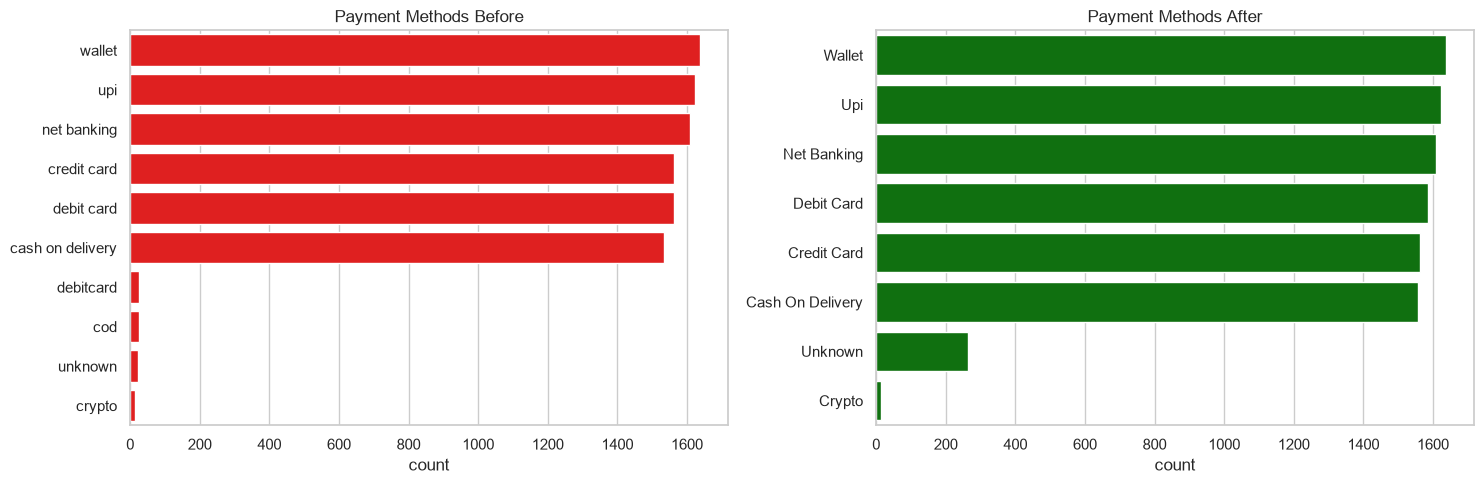

In [ ]:
#create a subplot for demonstration
fig,axes = plt.subplots(1,2,figsize=(15,5))

#Lets check all distinct values in the column
print("Unique Payment_Method values before Cleaning:",df['Payment_Method'].value_counts(dropna=False))
p1 = sns.countplot(df["Payment_Method"],ax=axes[0],order=df['Payment_Method'].value_counts().index)
p1.set(ylabel='',title='Payment Methods Before')
#Since its categorical type data. We see that same categories are present multiple times, due to minor issues during data entry. Lets correct them
df['Payment_Method'] = df['Payment_Method'].replace('debitcard','debit card')
df['Payment_Method'] = df['Payment_Method'].replace('cod', 'cash on delivery')
#Our data is almost all cleaned up. We have 2 distinct values 'NaN' and 'unknown'. We can fill all NaN values with unknown to retain the data.
df.fillna({'Payment_Method' : 'unknown' },inplace=True)
#Lets format the values a bit by applying title case
df['Payment_Method'] = df['Payment_Method'].str.title()
print(df['Payment_Method'].value_counts(dropna=False))
#Now that our column is cleaned, we can convert the dtype to category for better excution efficiency
df['Payment_Method'] = df['Payment_Method'].astype('category')
p2 = sns.countplot(df['Payment_Method'],ax=axes[1],color='purple',order=df['Payment_Method'].value_counts().index)
p2.set(ylabel='',title='Payment Methods After')
fig.tight_layout()
plt.show()

fig.savefig("./reports/03_payment_methods_cleaning.png")
plt.close()

Clean Is_Returned column

Values in Is_Returned column: Is_Returned
False    8127
True     1438
<NA>      287
Name: count, dtype: Int64
Values in the column after cleaning: Is_Returned
False    8127
True     1438
<NA>      287
Name: count, dtype: Int64


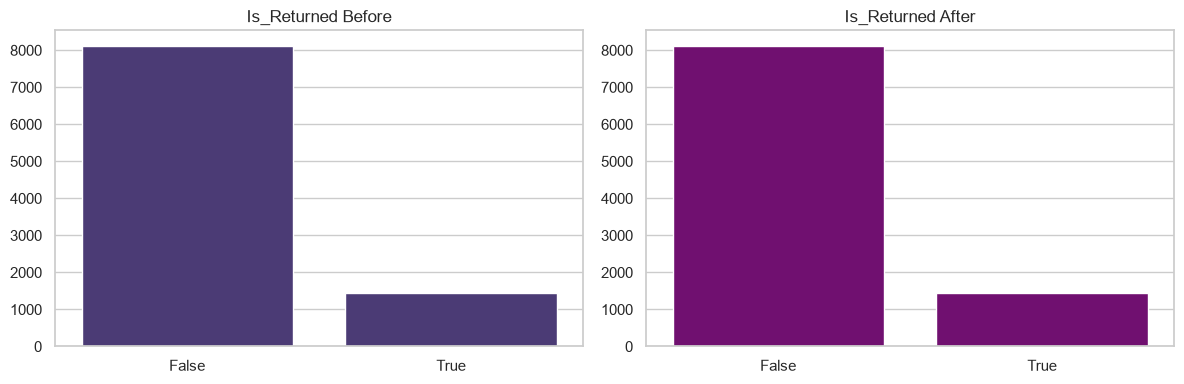

In [157]:
fig,axes = plt.subplots(1,2,figsize=(12,4))
#Lets check the values in the column
print("Values in Is_Returned column:",df['Is_Returned'].value_counts(dropna=False))
g1 = sns.countplot(x=df['Is_Returned'].astype('str'),ax=axes[0])
g1.set(xlabel='',ylabel='',title='Is_Returned Before')
#We can see the column contains various values that should be cleaned so it only contains 1,0 and NaN values
df['Is_Returned'] = df['Is_Returned'].replace(['true','yes','1','y','returned'],1)
df['Is_Returned'] = df['Is_Returned'].replace(['false','not returned','n','no','0'],0)
#Now that the column is cleaned, we can change its dtype to boolean not bool, so it can include NaN values
df['Is_Returned'] = df['Is_Returned'].astype('boolean')

print("Values in the column after cleaning:",df['Is_Returned'].value_counts(dropna=False))
g2 = sns.countplot(x=df['Is_Returned'].astype('str'),color='purple',ax=axes[1])
g2.set(xlabel='',ylabel='',title='Is_Returned After')
#setup  and export figure
fig.tight_layout()
plt.show()
fig.savefig("./reports/04_is_returned_cleaning.png")
plt.close()

Clean Customer_Email column

In [153]:
#Lets check the values
print(df['Customer_Email'].value_counts(dropna=False))
#There are a lot of empty records and even more invalid records. Lets handle all invalid entries and turn them to NaN
email_regex = r"^[\w\.-]+@[\w\.-]+\.\w+$"
invalid_email = df['Customer_Email'].notna() & ~df['Customer_Email'].str.match(email_regex,na=False)
df.loc[invalid_email,'Customer_Email'] = np.nan
df['Customer_Email'].value_counts(dropna=False)
#We have 560 NaN records. Thats a big number.
#Instead of amputating them, its better to add a new column called 'Has_Email', so we can preserve the records
df['Has_Email'] = df['Customer_Email'].notna()
df.head()

Customer_Email
NaN                         366
missing-at-symbol.com        45
test @gmail.com              44
customer@gmail.com           43
customer.gmail.com           36
                           ... 
customer5662@gmail.com        1
customer6478@example.com      1
customer2126@yahoo.com        1
customer8987@yahoo.com        1
customer2306@gmail.com        1
Name: count, Length: 9266, dtype: int64


,Order_ID,Customer_Age,Order_Amount,Order_Date,Payment_Method,Is_Returned,Customer_Email,Order_Year,Order_Month,Has_Email
0,ORD104099,32,1430.09,2026-08-15 06:05:10,Upi,False,customer4099@outlook.com,2026,August,True
1,ORD108672,36,3340.73,2025-05-09 00:25:06,Wallet,False,customer8672@example.com,2025,May,True
2,ORD107467,24,2724.27,2025-06-20 18:31:44,Wallet,True,customer7467@yahoo.com,2025,June,True
3,ORD100738,62,813.43,2026-07-01 15:39:18,Wallet,False,customer738@yahoo.com,2026,July,True
4,ORD105622,70,209.92,2026-07-24 08:20:24,Debit Card,False,customer5622@gmail.com,2026,July,True


## 7: Missingness Strategy, Imputation & Final Verification

#### Document column-by-column missingness treatment, apply safe demographic imputation, and verify the final schema